# Complete Stylometric Analysis Pipeline



This notebook runs the entire text analysis pipeline step by step, validates each stage, and produces plots so you can see the results clearly.

**Steps included:**
1. Load and validate corpus
2. Clean text and verify preprocessing
3. Process text with spaCy
4. Extract stylometric and character n-gram features
5. Generate synthetic datasets with controlled signals
6. Evaluate simple baselines
7. Compute similarity and drift metrics
8. Plot distributions and validation results
9. Summarize outputs and confirm correctness


In [1]:
import time
import re
import string
import random
from pathlib import Path

import numpy as np
import pandas as pd
import spacy
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

try:
    import seaborn as sns
except ImportError:
    sns = None

start_time = time.time()
# Use the corpus rebuilt directly from data/texts/
DATA_PATH = Path('data/generated/pan25_100_max500/corpus_from_texts.csv')
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

random.seed(42)
np.random.seed(42)
nlp = spacy.load('en_core_web_sm')

print('Setup complete')
print(f'Data path: {DATA_PATH}')
print(f'Output directory: {OUTPUT_DIR}')


Setup complete
Data path: data\generated\pan25_100_max500\corpus_from_texts.csv
Output directory: outputs


## 1. Load and validate the corpus

Check that the dataset is present, contains required columns, and that the label and rewrite distributions look correct.


In [2]:
df = pd.read_csv(DATA_PATH)
required_cols = {'id', 'source_id', 'class', 'rewrite_level', 'text'}
missing = required_cols - set(df.columns)
if missing:
    raise ValueError(f'Missing required columns: {missing}')

print('Loaded rows:', len(df))
print('Columns:', df.columns.tolist())
print('Class distribution:')
print(df['class'].value_counts())
print('Rewrite distribution:')
print(df['rewrite_level'].value_counts())

df.head(5)


Loaded rows: 598
Columns: ['id', 'source_id', 'class', 'rewrite_level', 'text']
Class distribution:
class
hybrid          298
ai_generated    200
human           100
Name: count, dtype: int64
Rewrite distribution:
rewrite_level
none      300
high      100
low        99
medium     99
Name: count, dtype: int64


,id,source_id,class,rewrite_level,text
0,pan25_dev_human_0025299,pan25_dev_human_0025299,human,none,"She tied her long blond hair in a ponytail, a ..."
1,pan25_dev_human_0031813,pan25_dev_human_0031813,human,none,I read the authors' response and maintain my r...
2,pan25_dev_human_0037211,pan25_dev_human_0037211,human,none,"when someone asks you for advice , who do you ..."
3,pan25_dev_human_0039079,pan25_dev_human_0039079,human,none,This paper explores the ability of nonlinear r...
4,pan25_dev_human_0045405,pan25_dev_human_0045405,human,none,An Old Captivity is a novel by British author ...


## 2. Clean text and verify preprocessing

Apply text normalization, lowercase the text, and verify that the cleaning step actually transforms the dataset as expected.


In [3]:
def basic_clean(text: str) -> str:
    text = str(text)
    text = text.replace('&amp;', '&')
    text = re.sub(r'\s+', ' ', text.strip())
    text = text.lower()
    return text

print('Example before cleaning:')
print(df['text'].iloc[0][:200])

df['clean_text'] = df['text'].apply(basic_clean)

print('Example after cleaning:')
print(df['clean_text'].iloc[0][:200])

amp_before = df['text'].str.contains('&amp;').sum()
amp_after = df['clean_text'].str.contains('&amp;').sum()
spaces_before = df['text'].str.contains(r'\s{2,}').sum()
spaces_after = df['clean_text'].str.contains(r'\s{2,}').sum()
print(f'HTML entity count before: {amp_before}, after: {amp_after}')
print(f'Multiple spaces before: {spaces_before}, after: {spaces_after}')

assert amp_after == 0, 'HTML entity replacement failed'
assert spaces_after <= spaces_before, 'Whitespace normalization failed'
print('Preprocessing validation passed')


Example before cleaning:
She tied her long blond hair in a ponytail, a sign that she was serious._SEP_The plan needed to be executed perfectly and she was short on time._SEP_The first person to come to mind was someone to kee
Example after cleaning:
she tied her long blond hair in a ponytail, a sign that she was serious._sep_the plan needed to be executed perfectly and she was short on time._sep_the first person to come to mind was someone to kee
HTML entity count before: 0, after: 0
Multiple spaces before: 349, after: 0
Preprocessing validation passed


## 3. spaCy linguistic processing

Process contained text with spaCy to derive tokens, part-of-speech tags, sentence boundaries, lemmas, and dependency structure.


In [4]:
print('Running spaCy processing...')
df['doc'] = list(nlp.pipe(df['clean_text'], disable=[]))
empty_docs = sum(1 for doc in df['doc'] if len(doc) == 0)
print('Documents processed:', len(df['doc']))
print('Empty docs:', empty_docs)
assert empty_docs == 0, 'Some documents are empty after spaCy processing'

sample_doc = df['doc'].iloc[0]
print('Sample tokens:', [t.text for t in sample_doc][:15])
print('Sample POS tags:', [t.pos_ for t in sample_doc][:15])
print('Sample lemmas:', [t.lemma_ for t in sample_doc][:15])
print('Sentence count:', len(list(sample_doc.sents)))

print('Sample sentence boundaries:', [sent.text for sent in sample_doc.sents][:3])

Running spaCy processing...
Documents processed: 598
Empty docs: 0
Sample tokens: ['she', 'tied', 'her', 'long', 'blond', 'hair', 'in', 'a', 'ponytail', ',', 'a', 'sign', 'that', 'she', 'was']
Sample POS tags: ['PRON', 'VERB', 'PRON', 'ADJ', 'ADJ', 'NOUN', 'ADP', 'DET', 'NOUN', 'PUNCT', 'DET', 'NOUN', 'SCONJ', 'PRON', 'AUX']
Sample lemmas: ['she', 'tie', 'her', 'long', 'blond', 'hair', 'in', 'a', 'ponytail', ',', 'a', 'sign', 'that', 'she', 'be']
Sentence count: 2
Sample sentence boundaries: ["she tied her long blond hair in a ponytail, a sign that she was serious._sep_the plan needed to be executed perfectly and she was short on time._sep_the first person to come to mind was someone to keep the target pre-occupied._sep_she knew a guy, but he was a complete clown._sep_he owes her though, back when he missed his target at the ringling brothers show in cabo._sep_she was sure she could get him to help so she made the call._sep_it wasn't to difficult to convince him but he agreed to the jo

## 4. Feature extraction

Extract stylometric feature vectors and verify there are no missing values.


In [5]:
FUNCTION_WORDS = [
    'a', 'an', 'the', 'and', 'or', 'but', 'if', 'while', 'although', 'because', 'since', 'though',
    'of', 'in', 'on', 'at', 'by', 'for', 'with', 'from', 'to', 'into', 'over', 'under', 'between', 'through',
    'is', 'are', 'was', 'were', 'be', 'been', 'being',
    'do', 'does', 'did', 'have', 'has', 'had',
    'can', 'could', 'may', 'might', 'must', 'shall', 'should', 'will', 'would',
    'i', 'you', 'he', 'she', 'it', 'we', 'they',
    'me', 'him', 'her', 'us', 'them',
    'my', 'your', 'his', 'its', 'our', 'their',
    'this', 'that', 'these', 'those',
    'who', 'whom', 'which', 'what',
    'as', 'than', 'so', 'not', 'no', 'nor', 'too', 'very'
]
POS_TAGS = [
    'ADJ', 'ADP', 'ADV', 'AUX', 'CCONJ', 'DET', 'INTJ', 'NOUN',
    'NUM', 'PART', 'PRON', 'PROPN', 'PUNCT', 'SCONJ', 'SYM', 'VERB', 'X'
]

def safe_divide(a, b):
    return a / b if b != 0 else 0.0

def get_lower_alpha_tokens(doc):
    return [t.text.lower() for t in doc if t.is_alpha]

def function_word_features(doc):
    tokens = get_lower_alpha_tokens(doc)
    counts = {w: 0 for w in FUNCTION_WORDS}
    for tok in tokens:
        if tok in counts:
            counts[tok] += 1
    total = len(tokens)
    return {f'fw_{w}': safe_divide(counts[w], total) for w in FUNCTION_WORDS}

def pos_features(doc):
    tokens = [t for t in doc if t.is_alpha]
    counts = {p: 0 for p in POS_TAGS}
    for tok in tokens:
        if tok.pos_ in counts:
            counts[tok.pos_] += 1
    total = len(tokens)
    return {f'pos_{p}': safe_divide(counts[p], total) for p in POS_TAGS}

def sentence_features(doc):
    sents = list(doc.sents)
    lengths = []
    clause_markers = {'SCONJ', 'CCONJ'}
    clause_count = 0
    for sent in sents:
        words = [t for t in sent if t.is_alpha]
        if words:
            lengths.append(len(words))
        clause_count += sum(1 for t in sent if t.pos_ in clause_markers)
    total = len(sents)
    avg_len = float(np.mean(lengths)) if lengths else 0.0
    return {
        'num_sentences': total,
        'avg_sentence_length': avg_len,
        'std_sentence_length': float(np.std(lengths)) if lengths else 0.0,
        'min_sentence_length': float(np.min(lengths)) if lengths else 0.0,
        'max_sentence_length': float(np.max(lengths)) if lengths else 0.0,
        'clause_per_sentence_ratio': safe_divide(clause_count, total)
    }

def lexical_features(doc):
    tokens = get_lower_alpha_tokens(doc)
    total = len(tokens)
    unique_tokens = len(set(tokens))
    return {
        'num_tokens': total,
        'num_unique_tokens': unique_tokens,
        'type_token_ratio': safe_divide(unique_tokens, total),
        'avg_token_length': float(np.mean([len(t) for t in tokens])) if tokens else 0.0
    }

def dependency_features(doc):
    depths = []
    for sent in doc.sents:
        for tok in sent:
            if not tok.is_alpha:
                continue
            depth = 0
            current = tok
            while current.head != current:
                depth += 1
                current = current.head
            depths.append(depth)
    return {
        'avg_dependency_depth': float(np.mean(depths)) if depths else 0.0,
        'max_dependency_depth': float(np.max(depths)) if depths else 0.0
    }

print('Feature extraction functions defined')


Feature extraction functions defined


In [6]:
print('Extracting stylometric features...')
feature_rows = []
for idx, row in df.iterrows():
    doc = row['doc']
    feats = {}
    feats.update(function_word_features(doc))
    feats.update(pos_features(doc))
    feats.update(sentence_features(doc))
    feats.update(lexical_features(doc))
    feats.update(dependency_features(doc))
    feature_rows.append(feats)

stylometric_df = pd.concat([df[['id', 'source_id', 'class', 'rewrite_level']].reset_index(drop=True), pd.DataFrame(feature_rows)], axis=1)
print('Stylometric feature matrix shape:', stylometric_df.shape)
nan_count = stylometric_df.isnull().sum().sum()
print('Missing feature values:', nan_count)
assert nan_count == 0, 'Missing values found in stylometric features'
stylometric_df.to_csv(OUTPUT_DIR / 'stylometric_features.csv', index=False)
print('Saved stylometric_features.csv')


Extracting stylometric features...
Stylometric feature matrix shape: (598, 115)
Missing feature values: 0
Saved stylometric_features.csv


In [7]:
print('Extracting character n-gram features...')
char_vectorizer = CountVectorizer(analyzer='char', ngram_range=(3,5), lowercase=True, min_df=1)
X_char = char_vectorizer.fit_transform(df['clean_text'])
char_feature_names = char_vectorizer.get_feature_names_out()
char_df = pd.DataFrame(X_char.toarray(), index=df['id'], columns=[f'char_ngram_{i}' for i in range(len(char_feature_names))])
print('Character n-gram matrix shape:', char_df.shape)
char_df.to_csv(OUTPUT_DIR / 'char_ngram_matrix.csv')
print('Saved char_ngram_matrix.csv')


Extracting character n-gram features...
Character n-gram matrix shape: (598, 106618)
Saved char_ngram_matrix.csv


## 5. Synthetic dataset validation

Create synthetic examples where the relationship between words and class is known, then verify the pipeline can detect that relationship.


In [8]:
def make_synth_c(n):
    rows = []
    for i in range(n):
        is_ai = random.choice([True, False])
        letters = list(string.ascii_uppercase)
        if is_ai:
            text = 'C ' + ' '.join(random.choices(letters, k=49))
        else:
            text = ' '.join(random.choices([l for l in letters if l != 'C'], k=50))
        rows.append({'id': f'synthC_{i}', 'source_id': f'sourceC_{i//10}', 'class': 'ai' if is_ai else 'human', 'rewrite_level': 'original', 'text': text})
    return pd.DataFrame(rows)

def make_synth_between(n):
    rows = []
    base = ['the', 'quick', 'brown', 'fox', 'jumps', 'over', 'lazy', 'dog']
    for i in range(n):
        is_ai = random.choice([True, False])
        if is_ai:
            text = ' '.join(base + ['between'] + random.choices(base, k=10))
        else:
            text = ' '.join(random.choices(base, k=15))
        rows.append({'id': f'synthB_{i}', 'source_id': f'sourceB_{i//10}', 'class': 'ai' if is_ai else 'human', 'rewrite_level': 'original', 'text': text})
    return pd.DataFrame(rows)

synth_token_c = make_synth_c(200)
synth_between = make_synth_between(200)
synth_shuffled = synth_token_c.copy()
synth_shuffled['class'] = np.random.permutation(synth_shuffled['class'].values)

print('Synthetic datasets created')
print('token_c counts:', synth_token_c['class'].value_counts().to_dict())
print('between counts:', synth_between['class'].value_counts().to_dict())

def check_signal(df, feature_text):
    signal = df['text'].str.contains(feature_text).astype(int)
    label = (df['class'] == 'ai').astype(int)
    return np.corrcoef(signal, label)[0, 1]

print('Correlation C->AI:', check_signal(synth_token_c, 'C'))
print('Correlation between->AI:', check_signal(synth_between, 'between'))
print('Correlation C->AI shuffled:', check_signal(synth_shuffled, 'C'))

synth_token_c.to_csv(OUTPUT_DIR / 'synthetic_token_c.csv', index=False)
synth_between.to_csv(OUTPUT_DIR / 'synthetic_word_between.csv', index=False)
synth_shuffled.to_csv(OUTPUT_DIR / 'synthetic_shuffled.csv', index=False)
print('Saved synthetic datasets')


Synthetic datasets created
token_c counts: {'human': 102, 'ai': 98}
between counts: {'ai': 108, 'human': 92}
Correlation C->AI: 1.0
Correlation between->AI: 0.9999999999999999
Correlation C->AI shuffled: 0.05962384953981581
Saved synthetic datasets


## 6. Synthetic Baseline evaluation

Evaluate majority, random, and shuffled baselines on the synthetic datasets.


In [9]:
def majority_pred(y):
    top = y.value_counts().idxmax()
    return [top] * len(y)

def random_pred(y):
    return np.random.choice(y.unique(), size=len(y))

def shuffled_pred(y):
    return np.random.permutation(y.values)

for name, df_synth in [('token_c', synth_token_c), ('word_between', synth_between), ('shuffled', synth_shuffled)]:
    print('---')
    print('Dataset:', name)
    y = df_synth['class']
    for label, func in [('majority', majority_pred), ('random', random_pred), ('shuffled', shuffled_pred)]:
        preds = func(y)
        score = f1_score(y, preds, pos_label='ai', average='binary')
        print(f'  {label} F1 = {score:.3f}')

print('Baseline evaluation complete')


---
Dataset: token_c
  majority F1 = 0.000
  random F1 = 0.429
  shuffled F1 = 0.541
---
Dataset: word_between
  majority F1 = 0.701
  random F1 = 0.569
  shuffled F1 = 0.519
---
Dataset: shuffled
  majority F1 = 0.000
  random F1 = 0.412
  shuffled F1 = 0.490
Baseline evaluation complete


## 7. Similarity and drift metrics

Compute pairwise similarity matrices and compare rewritten text to original sources.


In [10]:
numeric_cols = [c for c in stylometric_df.columns if c not in ['id', 'source_id', 'class', 'rewrite_level']]

# Standardize numeric stylometric features before similarity/distance.
scaler = StandardScaler()
X_stylo = scaler.fit_transform(stylometric_df[numeric_cols].values)

cos_stylo = cosine_similarity(X_stylo)
euc_stylo = euclidean_distances(X_stylo)
cos_stylo_df = pd.DataFrame(cos_stylo, index=stylometric_df['id'], columns=stylometric_df['id'])
euc_stylo_df = pd.DataFrame(euc_stylo, index=stylometric_df['id'], columns=stylometric_df['id'])

cos_char = cosine_similarity(X_char)
euc_char = euclidean_distances(X_char)
cos_char_df = pd.DataFrame(cos_char, index=df['id'], columns=df['id'])
euc_char_df = pd.DataFrame(euc_char, index=df['id'], columns=df['id'])

cos_stylo_df.to_csv(OUTPUT_DIR / 'stylometric_cosine_similarity.csv')
euc_stylo_df.to_csv(OUTPUT_DIR / 'stylometric_euclidean_distance.csv')
cos_char_df.to_csv(OUTPUT_DIR / 'char_ngram_cosine_similarity.csv')
euc_char_df.to_csv(OUTPUT_DIR / 'char_ngram_euclidean_distance.csv')
print('Saved similarity matrices')


Saved similarity matrices


In [11]:
rows = []
for source_id, group in stylometric_df.groupby('source_id'):
    ids = list(group['id'])
    if source_id not in ids:
        continue
    original_id = source_id
    for current_id in ids:
        if current_id == original_id:
            continue
        rows.append({
            'source_id': source_id,
            'original_id': original_id,
            'comparison_id': current_id,
            'comparison_class': group.loc[group['id'] == current_id, 'class'].values[0],
            'comparison_rewrite_level': group.loc[group['id'] == current_id, 'rewrite_level'].values[0],
            'stylometric_cosine_similarity': cos_stylo_df.loc[original_id, current_id],
            'stylometric_euclidean_distance': euc_stylo_df.loc[original_id, current_id],
            'char_ngram_cosine_similarity': cos_char_df.loc[original_id, current_id],
            'char_ngram_euclidean_distance': euc_char_df.loc[original_id, current_id],
        })
drift_df = pd.DataFrame(rows)
for col in ['stylometric_cosine_similarity', 'stylometric_euclidean_distance', 'char_ngram_cosine_similarity', 'char_ngram_euclidean_distance']:
    drift_df[col] = pd.to_numeric(drift_df[col], errors='coerce')

drift_df.to_csv(OUTPUT_DIR / 'drift_summary.csv', index=False)
print('Saved drift_summary.csv')
print('Drift comparisons:', len(drift_df))


Saved drift_summary.csv
Drift comparisons: 498


## 8. Visualizations

Plot class distributions, synthetic signal, and drift distributions so you can inspect the results visually.


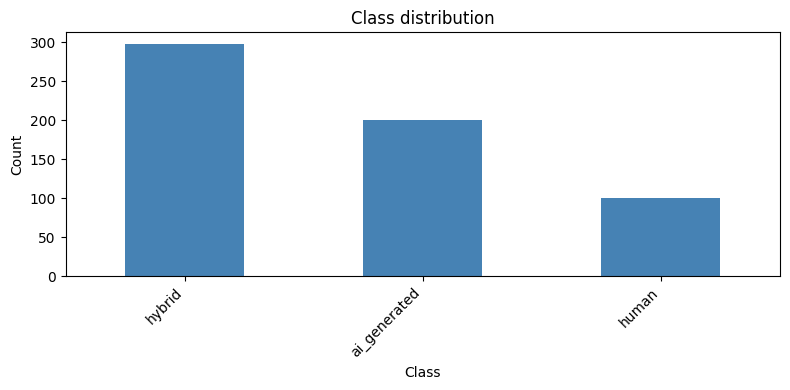

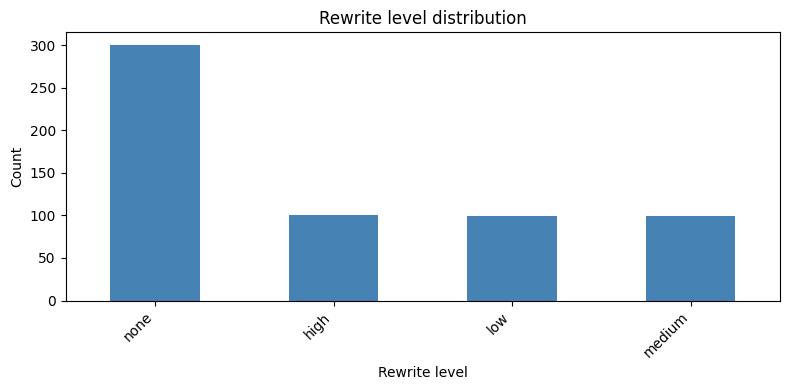

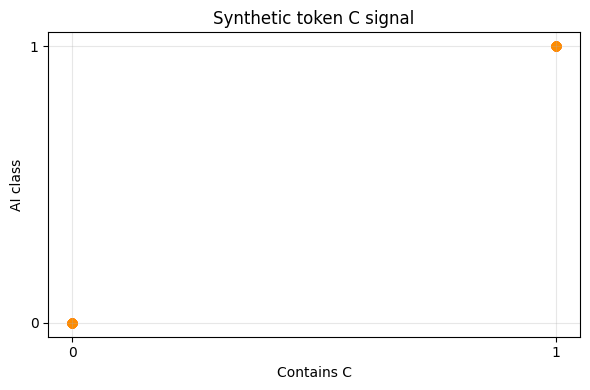

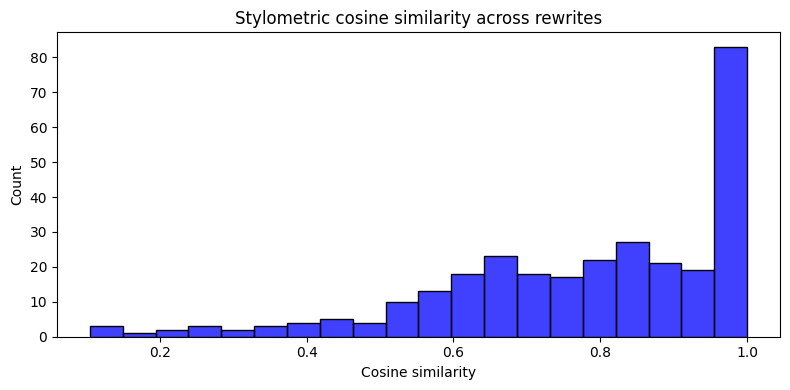

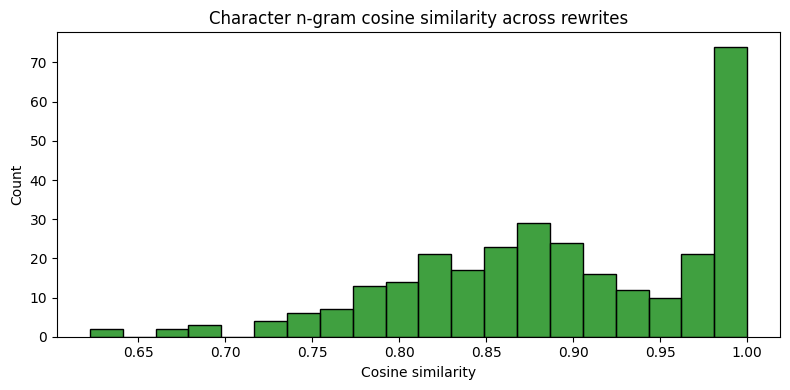

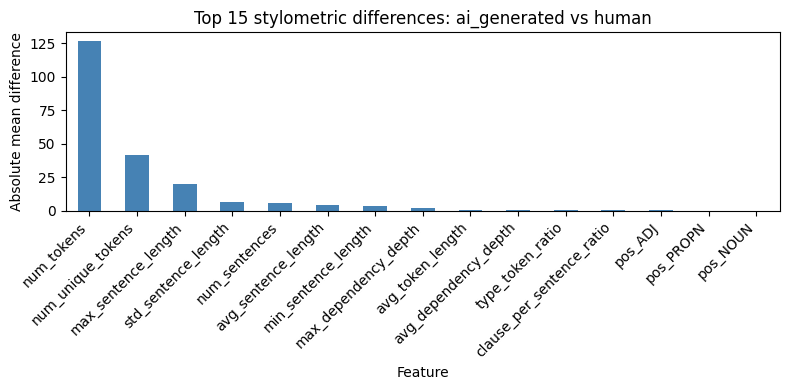

In [12]:
def plot_bar(series, title, xlabel, ylabel):
    fig, ax = plt.subplots(figsize=(8, 4))
    series.plot(kind='bar', ax=ax, color='steelblue')
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

plot_bar(df['class'].value_counts(), 'Class distribution', 'Class', 'Count')
plot_bar(df['rewrite_level'].value_counts(), 'Rewrite level distribution', 'Rewrite level', 'Count')

signal = (synth_token_c['text'].str.contains('C')).astype(int)
label = (synth_token_c['class'] == 'ai').astype(int)
plt.figure(figsize=(6, 4))
plt.scatter(signal, label, alpha=0.5, color='darkorange')
plt.title('Synthetic token C signal')
plt.xlabel('Contains C')
plt.ylabel('AI class')
plt.xticks([0, 1])
plt.yticks([0, 1])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
if sns is not None:
    sns.histplot(drift_df['stylometric_cosine_similarity'].astype(float).dropna(), bins=20, kde=False, color='blue')
else:
    plt.hist(drift_df['stylometric_cosine_similarity'].astype(float).dropna(), bins=20, color='blue')
plt.title('Stylometric cosine similarity across rewrites')
plt.xlabel('Cosine similarity')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
if sns is not None:
    sns.histplot(drift_df['char_ngram_cosine_similarity'].astype(float).dropna(), bins=20, kde=False, color='green')
else:
    plt.hist(drift_df['char_ngram_cosine_similarity'].astype(float).dropna(), bins=20, color='green')
plt.title('Character n-gram cosine similarity across rewrites')
plt.xlabel('Cosine similarity')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

feature_means = stylometric_df.groupby('class')[numeric_cols].mean().T
available_classes = set(feature_means.columns)
if 'ai' in available_classes and 'human' in available_classes:
    class_a, class_b = 'ai', 'human'
elif 'ai_generated' in available_classes and 'human' in available_classes:
    class_a, class_b = 'ai_generated', 'human'
elif 'hybrid' in available_classes and 'human' in available_classes:
    class_a, class_b = 'hybrid', 'human'
else:
    class_a, class_b = None, None

if class_a is not None:
    feature_diff = (feature_means[class_a] - feature_means[class_b]).abs().sort_values(ascending=False).head(15)
    plot_bar(feature_diff, f'Top 15 stylometric differences: {class_a} vs {class_b}', 'Feature', 'Absolute mean difference')
else:
    print('Skipping top feature difference plot; available classes:', sorted(available_classes))


## 9. Final validation and summary

Confirm that all outputs exist and that the pipeline completed correctly.


In [13]:
print('Output files:')
for name in ['stylometric_features.csv', 'char_ngram_matrix.csv', 'stylometric_cosine_similarity.csv', 'stylometric_euclidean_distance.csv', 'char_ngram_cosine_similarity.csv', 'char_ngram_euclidean_distance.csv', 'drift_summary.csv', 'synthetic_token_c.csv', 'synthetic_word_between.csv', 'synthetic_shuffled.csv']:
    path = OUTPUT_DIR / name
    print(f'{name}:', path.exists())

print('Total rows:', len(df))
print('Feature columns:', len(numeric_cols))
print('Synthetic validation datasets contain known signals for debugging and correctness.')
print('Pipeline finished in', round(time.time() - start_time, 2), 'seconds')


Output files:
stylometric_features.csv: True
char_ngram_matrix.csv: True
stylometric_cosine_similarity.csv: True
stylometric_euclidean_distance.csv: True
char_ngram_cosine_similarity.csv: True
char_ngram_euclidean_distance.csv: True
drift_summary.csv: True
synthetic_token_c.csv: True
synthetic_word_between.csv: True
synthetic_shuffled.csv: True
Total rows: 598
Feature columns: 111
Synthetic validation datasets contain known signals for debugging and correctness.
Pipeline finished in 109.93 seconds
